# Thiếu log trong toàn bộ lịch sử

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Audit Mbd Full History Missingness

Nguồn: `src/audit_mbd_full_history_missingness.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/audit_mbd_full_history_missingness.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Measure >50% absent event-days before a fixed cutoff; aggregate output only.

Absence of a recorded event is NOT proof that data collection is missing.
The cutoff is kept at 2022-12-01; December never enters the inputs.
"""
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

from audit_mbd_temporal_coverage import integer, DAY_NS

ROOT = Path(__file__).resolve().parents[1]
BASE = ROOT / "data" / "MBD-mini"
OUT = ROOT / "docs" / "mbd_temporal_coverage"
MODS = ("trx", "geo", "dialog")
CUTOFF = pd.Timestamp("2022-12-01")


def stats(counts, denominator, cohort=None):
    counts = np.asarray(counts)
    if cohort is not None:
        counts = counts[cohort]
    absent_over_half = 2 * counts < denominator
    return {
        "clients": len(counts), "opportunities_per_client": int(denominator),
        "clients_no_events": int((counts == 0).sum()),
        "clients_absent_strictly_over_50_percent": int(absent_over_half.sum()),
        "percent_clients_absent_strictly_over_50_percent": float(absent_over_half.mean() * 100) if len(counts) else None,
        "clients_at_least_50_percent_observed": int((~absent_over_half).sum()),
        "observed_count_quantiles": {str(q): float(np.quantile(counts, q)) for q in (0, .25, .5, .75, .9, .95, 1)} if len(counts) else {},
    }


def valid_rows(table, mod, known_ids):
    positions = integer(pc.index_in(table["client_id"], value_set=known_ids), -1)
    times = integer(table["event_time"])
    raw = (positions >= 0) & pc.is_valid(table["event_time"]).to_numpy()
    valid = raw.copy()
    for name in table.column_names:
        if table[name].null_count:
            valid &= pc.is_valid(table[name]).to_numpy()
    if mod == "trx":
        valid &= np.isfinite(table["amount"].to_numpy())
    elif mod == "dialog":
        arr = table["embedding"].combine_chunks()
        valid &= integer(pc.list_value_length(arr), -1) == 768
        flat = pc.list_flatten(arr)
        bad = ~np.isfinite(flat.to_numpy(zero_copy_only=False))
        if bad.any():
            parents = integer(pc.list_parent_indices(arr))
            invalid_vectors = np.zeros(len(table), dtype=bool)
            invalid_vectors[parents[bad]] = True
            valid &= ~invalid_vectors
    return positions, times, raw, valid

In [4]:
def main():
    started = time.perf_counter()
    previous = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))
    client_table = pq.read_table(BASE / "client_split", columns=["client_id"])
    ids = client_table["client_id"].combine_chunks()
    n = len(ids)
    source_start = {m: pd.Timestamp(previous["modalities"][m]["min_valid_time"]).ceil("D") for m in MODS}
    baseline = min(source_start.values())
    common_start = max(source_start.values())
    days = (CUTOFF - baseline).days
    common_days = (CUTOFF - common_start).days
    offset_common = (common_start - baseline).days
    raw_daily = {m: np.zeros((n, days), dtype=bool) for m in MODS}
    clean_daily = {m: np.zeros((n, days), dtype=bool) for m in MODS}
    raw_counts = {m: np.zeros(n, dtype=np.int64) for m in MODS}
    clean_counts = {m: np.zeros(n, dtype=np.int64) for m in MODS}
    row_quality = {}
    for mod in MODS:
        files = sorted((BASE / "detail" / mod).rglob("*.parquet"))
        row_total = invalid_total = 0
        for file_number, path in enumerate(files, 1):
            t = pq.ParquetFile(path).read().combine_chunks()
            pos, times, raw, valid = valid_rows(t, mod, ids)
            row_total += len(t)
            invalid_total += int((~valid).sum())
            in_history = (times >= source_start[mod].value) & (times < CUTOFF.value)
            in_common = (times >= common_start.value) & (times < CUTOFF.value)
            for good, flags, counts in ((raw, raw_daily[mod], raw_counts[mod]),
                                        (valid, clean_daily[mod], clean_counts[mod])):
                selected = good & in_history
                flags[pos[selected], (times[selected] // DAY_NS - baseline.value // DAY_NS)] = True
                selected_common = good & in_common
                np.add.at(counts, pos[selected_common], 1)
            if file_number % 100 == 0:
                print(f"{mod}: {file_number}/{len(files)} files", flush=True)
        # Independent checks against the preceding full-file audit.
        assert row_total == previous["modalities"][mod]["rows"]
        assert invalid_total == previous["modalities"][mod]["invalid_rows"]
        assert np.all(clean_daily[mod] <= raw_daily[mod])
        row_quality[mod] = {"files": len(files), "all_source_rows_checked": row_total,
                            "invalid_source_rows": invalid_total,
                            "raw_rows_in_common_history": int(raw_counts[mod].sum()),
                            "valid_rows_in_common_history": int(clean_counts[mod].sum())}
        print(f"{mod}: complete", flush=True)
    result = {
        "date": "2026-11-05", "initial_clients": n,
        "cutoff_exclusive": str(CUTOFF),
        "common_history_start_inclusive": str(common_start),
        "common_history_days": common_days,
        "full_source_history_starts": {m: str(x) for m, x in source_start.items()},
        "full_source_history_days": {m: (CUTOFF - x).days for m, x in source_start.items()},
        "definitions": {
            "absent_event_day": "No retained event for an ID on the stored naive calendar date; does not distinguish no activity from missing collection.",
            "strictly_over_50_percent": "2 * observed_opportunities < total_opportunities; exactly 50% is not included.",
            "common_day_any_source": "A day is observed if at least one valid event occurs in any of trx/geo/dialog.",
            "common_source_day_cells": "354 days times 3 sources; a source-day is observed if that source has at least one valid event.",
            "common_event_envelope": "Inclusive calendar span from first to last event of a client; not continuous coverage.",
            "sources_missing_over_half": "No events in at least 2 out of 3 sources anywhere in the history.",
            "strict_event_quality": "Same all-column non-null and finite-value/768-element embedding rule as summary.json.",
        },
        "row_quality": row_quality,
    }
    for mode, daily in (("raw_id_time", raw_daily), ("strict_event_quality", clean_daily)):
        common = {m: daily[m][:, offset_common:] for m in MODS}
        combined = np.logical_or.reduce(list(common.values()))
        source_presence = np.stack([common[m].any(axis=1) for m in MODS], axis=1)
        any_client = source_presence.any(axis=1)
        all_client = source_presence.all(axis=1)
        active = combined.sum(axis=1)
        source_days = sum(x.sum(axis=1) for x in common.values())
        source_count = source_presence.sum(axis=1)
        first = combined.argmax(axis=1)
        last = common_days - 1 - combined[:, ::-1].argmax(axis=1)
        span = np.where(any_client, last - first + 1, 0)
        both_bounds = []
        for mod in MODS:
            a = common[mod]
            first_mod = a.argmax(axis=1)
            last_mod = common_days - 1 - a[:, ::-1].argmax(axis=1)
            both_bounds.append((first_mod, last_mod))
        shared_first = np.maximum.reduce([x[0] for x in both_bounds])
        shared_last = np.minimum.reduce([x[1] for x in both_bounds])
        shared_span = np.where(all_client, np.maximum(0, shared_last - shared_first + 1), 0)
        output = {
            "clients_any_source_in_history": int(any_client.sum()),
            "clients_all_three_sources_in_history": int(all_client.sum()),
            "any_source_active_days_all_initial_clients": stats(active, common_days),
            "any_source_active_days_among_clients_with_any_events": stats(active, common_days, any_client),
            "any_source_active_days_among_all_three_source_clients": stats(active, common_days, all_client),
            "per_source_active_days": {m: stats(common[m].sum(axis=1), common_days) for m in MODS},
            "source_day_cells_all_initial_clients": stats(source_days, 3 * common_days),
            "sources_available_all_initial_clients": stats(source_count, 3),
            "any_source_first_last_calendar_span": stats(span, common_days),
            "all_three_common_first_last_calendar_span": stats(shared_span, common_days),
            "source_specific_full_history_active_days": {
                m: stats(daily[m][:, (source_start[m] - baseline).days:].sum(axis=1),
                         (CUTOFF - source_start[m]).days) for m in MODS},
            "any_source_full_earliest_history_active_days": stats(np.logical_or.reduce(list(daily.values())).sum(axis=1), days),
        }
        result[mode] = output
    invalid_trx = raw_counts["trx"] - clean_counts["trx"]
    overhalf = (raw_counts["trx"] > 0) & (2 * invalid_trx > raw_counts["trx"])
    any_trx = raw_counts["trx"] > 0
    result["transaction_attribute_missingness_in_common_history"] = {
        "clients_with_raw_transactions": int(any_trx.sum()),
        "clients_over_half_recorded_transactions_fail_attribute_quality": int(overhalf.sum()),
        "percent_of_all_initial_clients": float(overhalf.mean() * 100),
        "percent_of_clients_with_raw_transactions": float(overhalf.sum() / any_trx.sum() * 100),
    }
    result["elapsed_seconds"] = time.perf_counter() - started
    (OUT / "full_history_missingness.json").write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    rows = []
    strict = result["strict_event_quality"]
    for name, value in strict.items():
        if isinstance(value, dict) and "clients" in value:
            rows.append({"metric": name, **{k: v for k, v in value.items() if k != "observed_count_quantiles"}})
    pd.DataFrame(rows).to_csv(OUT / "full_history_missingness.csv", index=False, encoding="utf-8-sig")
    print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)

In [5]:
if __name__ == "__main__":
    main()

trx: 100/400 files


trx: 200/400 files


trx: 300/400 files


trx: 400/400 files


trx: complete


geo: 100/460 files


... (6 outputs left out)

dialog: 300/415 files


dialog: 400/415 files


dialog: complete


{
  "date": "2026-11-05",
  "initial_clients": 100224,
  "cutoff_exclusive": "2022-12-01 00:00:00",
  "common_history_start_inclusive": "2021-12-12 00:00:00",
  "common_history_days": 354,
  "full_source_history_starts": {
    "trx": "2021-01-01 00:00:00",
    "geo": "2021-12-12 00:00:00",
    "dialog": "2021-02-11 00:00:00"
  },
  "full_source_history_days": {
    "trx": 699,
    "geo": 354,
    "dialog": 658
  },
  "definitions": {
    "absent_event_day": "No retained event for an ID on the stored naive calendar date; does not distinguish no activity from missing collection.",
    "strictly_over_50_percent": "2 * observed_opportunities < total_opportunities; exactly 50% is not included.",
    "common_day_any_source": "A day is observed if at least one valid event occurs in any of trx/geo/dialog.",
    "common_source_day_cells": "354 days times 3 sources; a source-day is observed if that source has at least one valid event.",
    "common_event_envelope": "Inclusive calendar span from 

In [6]:
show_generated_results(__eda_started_ns, 'src/audit_mbd_full_history_missingness.py')

### Kết quả: `src/audit_mbd_full_history_missingness.py`

**docs/mbd_temporal_coverage/full_history_missingness.csv** — 5 dòng đầu

,metric,clients,opportunities_per_client,clients_no_events,clients_absent_strictly_over_50_percent,percent_clients_absent_strictly_over_50_percent,clients_at_least_50_percent_observed
0,any_source_active_days_all_initial_clients,100224,354,1156,42320,42.225415,57904
1,any_source_active_days_among_clients_with_any_...,99068,354,0,41164,41.551258,57904
2,any_source_active_days_among_all_three_source_...,25695,354,0,4854,18.890835,20841
3,source_day_cells_all_initial_clients,100224,1062,1156,95227,95.014168,4997
4,sources_available_all_initial_clients,100224,3,1156,22329,22.279095,77895


File kết quả khác: `docs/mbd_temporal_coverage/full_history_missingness.json`

## Analyze Full Population Temporal Eda

Nguồn: `src/scripts/analyze_full_population_temporal_eda.py`. Chạy các ô của phần này theo thứ tự.

In [7]:
__file__ = str(ROOT / 'src/scripts/analyze_full_population_temporal_eda.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [8]:
"""Full-population retrospective EDA, all 12 label months and full raw log history.

No sampling, model fit, prediction cutoff, or causal identification. Unknown
adjacent labels and unobserved source months remain explicitly unavailable.
"""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import duckdb
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT=Path(__file__).resolve().parents[2]
OUT=ROOT/'outputs/full_population_temporal_eda_20261118'
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','figure.dpi':130,'axes.spines.top':False,'axes.spines.right':False})
SOURCES=['trx','geo','dialog']
STATES=['Neither adjacent month','Before next purchase only','After prior purchase only','Between two purchases','Adjacent label unknown']


def save(fig,name,note):
    fig.text(.01,.01,note,fontsize=8,color='#475569')
    fig.tight_layout(rect=(0,.06,1,.97))
    for ext in ['png','svg']:fig.savefig(OUT/f'{name}.{ext}',bbox_inches='tight')
    plt.close(fig)


def extract():
    c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2');c.execute('SET preserve_insertion_order=false')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp'")
    ids=c.execute(f"SELECT client_id FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/client_split/**/*.parquet')").df()
    assert ids.client_id.is_unique
    labels=c.execute(f"SELECT client_id,date_trunc('month',cast(mon AS DATE)) AS month,target_1,target_2,target_3,target_4 FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/targets/**/*.parquet')").df()
    target_cols=['target_1','target_2','target_3','target_4']
    assert labels[target_cols].isin([0,1]).all().all()
    labels['y']=labels[target_cols].max(axis=1)
    labels=labels[['client_id','month','y']]
    assert not labels.duplicated(['client_id','month']).any()
    assert labels.month.nunique()>=12
    assert labels.groupby('month').client_id.nunique().eq(len(ids)).all()
    assert set(labels.client_id)==set(ids.client_id)
    bounds=[];parts={}
    for source in SOURCES:
        print('Read ALL raw files:',source,flush=True)
        path=f'{ROOT.as_posix()}/data/MBD-mini/detail/{source}/**/*.parquet'
        b=c.execute(f"SELECT count(*) n,min(event_time) first_event,max(event_time) last_event FROM read_parquet('{path}')").df().iloc[0]
        extra=",coalesce(sum(amount) FILTER(WHERE currency=11),0) amount11" if source=='trx' else ''
        a=c.execute(f"SELECT client_id,date_trunc('month',event_time+INTERVAL '3 hours') AS month,count(*) {source}_events {extra} FROM read_parquet('{path}') GROUP BY 1,2").df()
        assert int(a[source+'_events'].sum())==int(b['n'])
        assert set(a.client_id).issubset(set(ids.client_id))
        first=pd.Timestamp(b.first_event)+pd.Timedelta(hours=3);last=pd.Timestamp(b.last_event)+pd.Timedelta(hours=3)
        # Source-month availability, not proof of continuous individual observation.
        start=first.to_period('M').to_timestamp();end=last.to_period('M').to_timestamp()
        bounds.append(dict(source=source,raw_rows=int(b['n']),first_event_moscow=str(first),last_event_moscow=str(last),first_month=str(start.date()),last_month=str(end.date()),first_month_partial=bool(first.day!=1)))
        a.to_parquet(OUT/f'{source}_monthly.parquet',index=False);parts[source]=a
    earliest=min(pd.Timestamp(b['first_month']) for b in bounds)
    latest=max(labels.month.max(),max(pd.Timestamp(b['last_month']) for b in bounds))
    months=pd.date_range(earliest,latest,freq='MS')
    panel=ids.merge(pd.DataFrame({'month':months}),how='cross')
    for b in bounds:
        s=b['source'];panel=panel.merge(parts[s],on=['client_id','month'],how='left',validate='one_to_one')
        in_range=panel.month.between(pd.Timestamp(b['first_month']),pd.Timestamp(b['last_month']))
        panel[s+'_available']=in_range
        panel[s+'_events']=panel[s+'_events'].where(~in_range,panel[s+'_events'].fillna(0))
        if s=='trx':panel['amount11']=panel.amount11.where(~in_range,panel.amount11.fillna(0))
    panel=panel.merge(labels,on=['client_id','month'],how='left',validate='one_to_one')
    labels.to_parquet(OUT/'labels_any.parquet',index=False)
    panel.to_parquet(OUT/'all_customer_months.parquet',index=False)
    pd.DataFrame(bounds).to_csv(OUT/'source_inventory.csv',index=False)
    return ids,labels,panel,bounds

In [9]:
def analyze(ids,labels,panel,bounds):
    n=len(ids);months=sorted(labels.month.unique());checks={}
    # Every customer retained at every label month; adjacent labels joined by date.
    d=panel[panel.month.isin(months)].copy()
    for shift,name in [(1,'previous_y'),(-1,'next_y')]:
        a=labels.rename(columns={'y':name}).copy();a['month']=a.month+pd.DateOffset(months=shift)
        d=d.merge(a,on=['client_id','month'],how='left',validate='one_to_one')
    known=d.previous_y.notna()&d.next_y.notna()
    d['state']=np.select([~known,d.previous_y.eq(0)&d.next_y.eq(0),d.previous_y.eq(0)&d.next_y.eq(1),d.previous_y.eq(1)&d.next_y.eq(0)],['Adjacent label unknown',STATES[0],STATES[1],STATES[2]],default=STATES[3])
    group_counts=d.groupby(['month','state']).size().unstack('state',fill_value=0).reindex(columns=STATES,fill_value=0)
    checks['all_monthly_groups_sum_to_all_clients']=bool(group_counts.sum(axis=1).eq(n).all())
    group_counts.to_csv(OUT/'monthly_partition_counts.csv')
    d.to_parquet(OUT/'label_month_panel_with_states.parquet',index=False)
    # Full calendar inventory, including all labelled months and missing source months.
    calendar=panel.groupby('month').agg(customers=('client_id','size'),trx_events=('trx_events',lambda v:v.sum(min_count=1)),geo_events=('geo_events',lambda v:v.sum(min_count=1)),dialog_events=('dialog_events',lambda v:v.sum(min_count=1)),buyers=('y',lambda v:v.sum(min_count=1)),labelled=('y','count')).reset_index()
    calendar.to_csv(OUT/'calendar_inventory.csv',index=False)
    fig,axes=plt.subplots(4,1,figsize=(14,10),sharex=True)
    for ax,col,title in zip(axes,['trx_events','geo_events','dialog_events','buyers'],['TRX raw events','GEO raw events','DIALOG raw events','Any-product positive customer-months']):
        ax.plot(calendar.month,calendar[col],marker='o',ms=3);ax.set_ylabel(title);ax.grid(alpha=.2)
        ax.axvspan(pd.Timestamp(months[0]),pd.Timestamp(months[-1]),color='#0d9488',alpha=.08)
    axes[0].set_title(f'Full inventory: {n:,} customers; {len(months)} label months; all available log months')
    save(fig,'01_full_calendar_inventory','NaN = source/label month unavailable; never zero-filled outside source range. Shading = label span. First source month may be partial (see inventory CSV).')
    fig,ax=plt.subplots(figsize=(14,5));bottom=np.zeros(len(group_counts))
    for state,color in zip(STATES,['#cbd5e1','#2563eb','#d97706','#0d9488','#a78bfa']):
        ax.bar(range(len(group_counts)),group_counts[state],bottom=bottom,label=state,color=color);bottom+=group_counts[state].to_numpy()
    ax.set_xticks(range(len(group_counts)),[pd.Timestamp(m).strftime('%Y-%m') for m in group_counts.index],rotation=35);ax.set_ylabel('Customers');ax.set_title('Every label month is partitioned into exhaustive adjacent-purchase groups');ax.legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.22),ncol=3)
    save(fig,'02_exhaustive_monthly_groups',f'Groups sum to {n:,} in EACH month. Labels at t-1 and t+1; month t may independently have a purchase. Edge labels remain unknown.')
    # Month-by-month before/after, without selecting a short balanced cohort.
    lag_rows=[]
    for lag in [-1,1]:
        base=labels.rename(columns={'month':'target_month'}).copy();base['month']=base.target_month+pd.DateOffset(months=lag)
        base=base.merge(panel.drop(columns='y'),on=['client_id','month'],how='left',validate='one_to_one')
        for (target,y),g in base.groupby(['target_month','y']):
            for s in SOURCES:
                observed=g[s+'_available'].fillna(False)
                k=int((g[s+'_events'].gt(0)&observed).sum());den=int(observed.sum())
                lag_rows.append(dict(target_month=target,lag=lag,purchase=int(y),source=s,total_customers=len(g),observed_customers=den,unavailable_customers=len(g)-den,active_customers=k,rate=k/den if den else np.nan))
    lag=pd.DataFrame(lag_rows);lag.to_csv(OUT/'before_after_monthly_rates.csv',index=False)
    rr=lag.pivot(index=['target_month','lag','source'],columns='purchase',values='rate').rename(columns={0:'nonbuyer_rate',1:'buyer_rate'}).reset_index();rr['rate_ratio']=rr.buyer_rate/rr.nonbuyer_rate.replace(0,np.nan)
    rr.to_csv(OUT/'before_after_monthly_rate_ratios.csv',index=False)
    fig,axes=plt.subplots(3,2,figsize=(15,9),sharex=True)
    for i,s in enumerate(SOURCES):
        for j,k in enumerate([-1,1]):
            ax=axes[i,j]
            for y,color,label in [(1,'#0d9488','Purchase in target month'),(0,'#64748b','No purchase in target month')]:
                a=lag[(lag.source==s)&(lag.lag==k)&(lag.purchase==y)].sort_values('target_month');ax.plot(a.target_month,a.rate,'o-',ms=4,color=color,label=label)
            ax.set_ylim(0,1);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title(s.upper()+(' in PREVIOUS month' if k==-1 else ' in FOLLOWING month'));ax.grid(alpha=.2)
            if i==0:ax.legend(fontsize=7)
    for ax in axes[-1]:ax.tick_params(axis='x',rotation=35)
    fig.suptitle('Before purchase vs after purchase | all customers and all 12 target months')
    save(fig,'03_before_vs_after_all_label_months','X = target month; Y = share with source events in t-1 or t+1. Gaps = missing follow-up, not zero. Repeated purchases included; observational, not causal.')
    # Distinguish prior vs following purchase conditional on whether same month buys.
    assoc=[]
    for (state,y),g in d.groupby(['state','y']):
        for s in SOURCES:
            observed=g[s+'_available'];den=int(observed.sum())
            assoc.append(dict(state=state,current_purchase=int(y),source=s,total_customer_months=len(g),observed_customer_months=den,unavailable_customer_months=len(g)-den,active=int((g[s+'_events'].gt(0)&observed).sum()),rate=g.loc[observed,s+'_events'].gt(0).mean() if den else np.nan))
    assoc=pd.DataFrame(assoc);assoc.to_csv(OUT/'adjacent_purchase_source_associations.csv',index=False)
    checks['state_by_current_label_exhausts_full_year']=int(assoc[assoc.source.eq('trx')].total_customer_months.sum())==len(labels)
    fig,axes=plt.subplots(2,3,figsize=(16,9),sharey=True)
    for i,y in enumerate([0,1]):
        for j,s in enumerate(SOURCES):
            ax=axes[i,j];a=assoc[(assoc.source==s)&(assoc.current_purchase==y)].set_index('state').reindex(STATES)
            ax.bar(range(5),a.rate,color=['#94a3b8','#2563eb','#d97706','#0d9488','#a78bfa']);ax.set_ylim(0,1.12);ax.set_yticks([0,.25,.5,.75,1]);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_xticks(range(5),['Neither','Before only','After only','Between','Unknown'],rotation=25)
            ax.set_title(f'{s.upper()} | purchase in current month = {y}')
            for z,v in enumerate(a.rate):
                if np.isfinite(v):ax.text(z,v+.015,f'{v:.1%}',ha='center',fontsize=8)
    fig.suptitle('Is source activity associated with a prior purchase or an upcoming purchase?')
    save(fig,'04_prior_next_purchase_groups','All 12 label months registered. Rates use source-observed months; n/unknown in CSV. Current-month purchase stratified; pooled customer-month rates, no independence or causal claim.')
    # Financial contribution on ALL raw TRX months; purchase-frequency groups exhaust ids.
    freq=labels.groupby('client_id').y.sum().rename('positive_months').reset_index()
    freq['purchase_group']=np.select([freq.positive_months.eq(0),freq.positive_months.eq(1)],['No purchase observed','One positive month'],default='Multiple positive months')
    value=panel[panel.trx_available].groupby('client_id').agg(amount11=('amount11','sum'),trx_events=('trx_events','sum')).reset_index()
    customer=ids.merge(freq,on='client_id',validate='one_to_one').merge(value,on='client_id',validate='one_to_one')
    totals=customer.groupby('purchase_group').agg(customers=('client_id','size'),amount11=('amount11','sum'),events=('trx_events','sum')).reindex(['No purchase observed','One positive month','Multiple positive months'])
    totals['customer_share']=totals.customers/n;totals['value_share']=totals.amount11/totals.amount11.sum();totals['event_share']=totals.events/totals.events.sum()
    totals.to_csv(OUT/'exhaustive_purchase_frequency_financial_groups.csv');customer.to_parquet(OUT/'all_customer_financial_groups.parquet',index=False)
    concentration=[]
    for metric in ['amount11','trx_events']:
        ranked=customer.sort_values(metric,ascending=False)
        for pct in [1,5,10,20]:
            size=int(np.ceil(n*pct/100));concentration.append(dict(metric=metric,top_pct=pct,top_customers=size,rest_customers=n-size,top_share=ranked.iloc[:size][metric].sum()/ranked[metric].sum()))
    concentration=pd.DataFrame(concentration);concentration.to_csv(OUT/'full_history_concentration.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(15,5));x=np.arange(3)
    for i,col,title in [(0,'customer_share','Customer share'),(1,'value_share','Transaction-value share'),(2,'event_share','Event-count share')]:axes[0].bar(x+(i-1)*.23,totals[col],.23,label=title)
    axes[0].set_xticks(x,['No positive month','One positive month','Multiple positive months']);axes[0].yaxis.set_major_formatter(PercentFormatter(1));axes[0].legend(fontsize=8);axes[0].set_title('Exhaustive customer groups: financial contribution')
    for metric,label in [('amount11','Transaction value (11)'),('trx_events','Transaction count')]:
        a=concentration[concentration.metric.eq(metric)];axes[1].plot(a.top_pct,a.top_share,'o-',label=label)
    axes[1].set_ylim(0,1);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_xlabel('Top % of customers (remainder retained in CSV)');axes[1].set_title('Concentration across full raw TRX history');axes[1].legend(fontsize=8)
    save(fig,'05_full_history_financial_contribution','ALL customers, ALL valid TRX months; amount only currency 11. Groups based on 12 label months, not revenue, ownership or lifetime purchases.')
    # First-source order uses ALL source history and ALL 12-month buyers; nonbuyers kept.
    first_buy=labels[labels.y.eq(1)].groupby('client_id').month.min().rename('first_buy')
    orders=[]
    for s in SOURCES:
        first_source=panel[panel[s+'_events'].gt(0)].groupby('client_id').month.min().rename('first_source')
        z=ids.merge(first_buy,on='client_id',how='left',validate='one_to_one').merge(first_source,on='client_id',how='left',validate='one_to_one')
        end=pd.Timestamp(next(b['last_month'] for b in bounds if b['source']==s))
        z['order']=np.select([z.first_buy.isna(),z.first_source.lt(z.first_buy),z.first_source.eq(z.first_buy),z.first_source.gt(z.first_buy),z.first_buy.ge(end)],['No purchase observed','Source observed before','First source in purchase month','First source after','No source; follow-up insufficient'],default='No source within available history')
        for state,g in z.groupby('order'):orders.append(dict(source=s,state=state,customers=len(g),share=len(g)/n))
    orders=pd.DataFrame(orders);orders.to_csv(OUT/'full_population_source_purchase_order.csv',index=False)
    order_states=['No purchase observed','Source observed before','First source in purchase month','First source after','No source within available history','No source; follow-up insufficient']
    a=orders.pivot(index='source',columns='state',values='share').reindex(index=SOURCES,columns=order_states).fillna(0)
    fig,ax=plt.subplots(figsize=(15,5));left=np.zeros(3)
    for state,color in zip(order_states,['#cbd5e1','#0d9488','#f59e0b','#6366f1','#64748b','#ec4899']):
        ax.barh(range(3),a[state],left=left,label=state,color=color);left+=a[state].to_numpy()
    ax.set_yticks(range(3),[s.upper() for s in SOURCES]);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_title(f'First observed source vs first observed purchase | all {n:,} customers');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2,fontsize=8)
    save(fig,'06_full_population_source_order','All valid source history and all 12 label months. Same-month order unknown; no-source cases retain follow-up status. First observed is not first-ever.')
    expected_figures={f'{index:02d}_{name}.png' for index,name in enumerate((
        'full_calendar_inventory', 'exhaustive_monthly_groups',
        'before_vs_after_all_label_months', 'prior_next_purchase_groups',
        'full_history_financial_contribution', 'full_population_source_order'), 1)}
    checks.update({'all_clients_each_label_month':bool(d.groupby('month').size().eq(n).all()),'all_12_months_in_lag_inventory':lag.target_month.nunique()==len(months),'before_after_groups_exhaust_month_population':bool(lag.groupby(['target_month','lag','source']).total_customers.sum().eq(n).all()),'observed_plus_unavailable_reconciles':bool((lag.observed_customers+lag.unavailable_customers).eq(lag.total_customers).all()),'financial_groups_exhaust_clients':int(totals.customers.sum())==n,'order_groups_exhaust_clients_each_source':bool(orders.groupby('source').customers.sum().eq(n).all()),'raw_trx_events_reconcile':int(customer.trx_events.sum())==next(b['raw_rows'] for b in bounds if b['source']=='trx'),'label_months_at_least_12':len(months)>=12,'six_figures':all((OUT/name).is_file() for name in expected_figures)})
    assert all(checks.values()),checks
    (OUT/'validation.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
    manifest={'customers':n,'label_months':[pd.Timestamp(m).strftime('%Y-%m') for m in months],'label_rows':len(labels),'sampled_customers':0,'raw_sources':bounds,'timezone':'Europe/Moscow','raw_naive_assumption':'UTC','method':'retrospective monthly alignment, no prediction cutoff/model, no causal claim','script_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest()}
    (OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    report=['# EDA toàn bộ khách — 12 tháng nhãn và toàn bộ lịch sử log','',f'Khách: {n:,}; nhãn: {len(labels):,} dòng qua {len(months)} tháng. Không lấy mẫu. Mỗi tháng phân nhóm đủ toàn bộ khách.','',
    '## Phương pháp và cách đọc','Tháng t có hoạt động được nối nhãn t−1 và t+1. Bốn nhóm known: không mua cả hai tháng kề; chỉ mua tháng sau; chỉ mua tháng trước; mua cả hai. Nhãn kề thiếu giữ nhóm unknown. Tách thêm nhãn mua cùng tháng 0/1 để không trộn tương tác cùng tháng với trước/sau.',
    'Biểu đồ 03 lấy từng tháng có nhãn làm mốc, so tỷ lệ có log tháng trước và tháng sau giữa người mua và không mua. Tất cả 12 tháng nhãn đều có trong bảng; không có log toàn nguồn trong tháng tương lai là unavailable, không phải 0. Do dữ liệu chỉ có 12 tháng nhãn, hai tháng biên không có đủ hai nhãn kề. Không thể có 12 tháng đầy đủ cả hai nhãn kề nếu không có nhãn bổ sung ngoài phạm vi.',
    'Biểu đồ 04 gộp khách–tháng trong phạm vi nguồn, có bảng n và unavailable; khách lặp qua tháng nên không dùng kiểm định độc lập theo dòng. Khác biệt có thể do lịch, lịch sử mua và yếu tố khác; chưa chứng minh hoạt động là hệ quả hoặc chuẩn bị mua.',
    'Biểu đồ 05 tính đóng góp tài chính trên toàn bộ thời gian TRX; chia khách theo số tháng dương trong toàn bộ kỳ nhãn. Không coi amount là doanh thu hoặc tiền tệ đã giải mã. Không đồng nhất nhãn không mua trong một năm với chưa từng mua trong đời.',
    'Biểu đồ 06 so tháng đầu tiên có nguồn trong toàn bộ log với tháng đầu tiên có nhãn mua, giữ cả người không mua và trạng thái chưa đủ theo dõi. Không xác định thứ tự bên trong cùng tháng.',
    'Số 0 trong tháng nguồn có dữ liệu nghĩa không tìm thấy sự kiện, không xác nhận không hoạt động thực tế. Phạm vi tháng nguồn không bảo đảm quan sát liên tục từng khách. Tháng đầu nguồn có thể không trọn; xem source_inventory.csv. Timestamp raw giả định UTC rồi chuyển lịch Moscow. Dialog có nhiễu ngày theo audit dự án, không suy lịch vận hành thực tế.',
    '', '## Kết quả phân nhóm tài chính (CSV lưu số chính xác)',totals.to_string(),'', '## Kiểm tra',json.dumps(checks,indent=2),
    '', '## Trạng thái artifact cũ','Kết quả purchase_event_financial_eda_20261118 dùng mẫu tham chiếu và chỉ một số tháng mua là phương pháp cũ, không đáp ứng yêu cầu mới. Gói hiện tại thay thế về phạm vi phân tích.']
    report.extend(['','## Phát hiện về hai chiều thời gian',
    'Trong các khách–tháng không có mua cùng tháng: DIALOG có log ở 22,64% nhóm chỉ mua tháng sau (2.041/9.016), 24,86% nhóm chỉ mua tháng trước (2.517/10.125), và 6,00% nhóm không mua hai tháng kề (58.284/971.491). Đây là tỷ lệ gộp quan sát của các tháng đủ nhãn kề 03–12/2022, không phải trên toàn bộ 12 tháng đều đủ nhãn kề. Kết quả cho thấy DIALOG gắn với cả hai phía thời gian, chưa xác định một cuộc hội thoại cụ thể là chuẩn bị hay hậu quả.',
    'Ở khách–tháng có mua cùng tháng, tỷ lệ DIALOG của nhóm chỉ mua tháng sau và chỉ mua tháng trước lần lượt 37,56% và 37,36%. Cần giữ việc tách nhãn cùng tháng để tránh gọi mọi hội thoại là tín hiệu đi trước.',
    'Các con số chi tiết và n theo từng tháng được lưu trong before_after_monthly_rates.csv; không chọn một vài tháng đẹp để kết luận toàn kỳ. Hai nhóm năm nhãn gồm 89.813 khách không có tháng dương, 8.496 khách đúng một tháng dương, 1.915 khách nhiều tháng dương; tổng 100.224. Tỷ trọng amount toàn lịch sử TRX tương ứng khoảng 92,36%, 6,39%, 1,26%; khác với kết quả chỉ riêng năm 2022 trước đây vì phạm vi thời gian đã mở rộng.'])
    (OUT/'REPORT.md').write_text('\n\n'.join(report),encoding='utf-8')
    print(json.dumps(manifest,indent=2),flush=True)
    print(totals.to_string(),flush=True)
    print(assoc[assoc.source.eq('dialog')].to_string(index=False),flush=True)

In [10]:
if __name__=='__main__':
    analyze(*extract())

Read ALL raw files: trx


Read ALL raw files: geo


Read ALL raw files: dialog


{
  "customers": 100224,
  "label_months": [
    "2022-02",
    "2022-03",
    "2022-04",
    "2022-05",
    "2022-06",
    "2022-07",
    "2022-08",
    "2022-09",
    "2022-10",
    "2022-11",
    "2022-12",
    "2023-01"
  ],
  "label_rows": 1202688,
  "sampled_customers": 0,
  "raw_sources": [
    {
      "source": "trx",
      "raw_rows": 38764930,
      "first_event_moscow": "2021-01-01 00:00:02.169545",
      "last_event_moscow": "2022-12-31 23:59:58.460193",
      "first_month": "2021-01-01",
      "last_month": "2022-12-01",
      "first_month_partial": false
    },
    {
      "source": "geo",
      "raw_rows": 66295724,
      "first_event_moscow": "2021-12-11 22:27:07.507106",
      "last_event_moscow": "2022-12-31 23:59:58.725788",
      "first_month": "2021-12-01",
      "last_month": "2022-12-01",
      "first_month_partial": true
    },
    {
      "source": "dialog",
      "raw_rows": 217205,
      "first_event_moscow": "2021-02-10 12:36:07.022271",
      "last_event_mo

                          customers      amount11      events  customer_share  value_share  event_share
purchase_group                                                                                         
No purchase observed          89813  4.610444e+13  31901417.0        0.896123     0.923553     0.822945
One positive month             8496  3.189389e+12   5181825.0        0.084770     0.063889     0.133673
Multiple positive months       1915  6.268757e+11   1681688.0        0.019107     0.012557     0.043382


                    state  current_purchase source  total_customer_months  observed_customer_months  unavailable_customer_months  active     rate
   Adjacent label unknown                 0 dialog                 198732                     99183                        99549    2415 0.024349
   Adjacent label unknown                 1 dialog                   1716                      1041                          675     243 0.233429
After prior purchase only                 0 dialog                  10125                     10125                            0    2517 0.248593
After prior purchase only                 1 dialog                    728                       728                            0     272 0.373626
Before next purchase only                 0 dialog                   9016                      9016                            0    2041 0.226375
Before next purchase only                 1 dialog                    663                       663                         

### Kết quả: `src/scripts/analyze_full_population_temporal_eda.py`

**outputs/full_population_temporal_eda_20261118/01_full_calendar_inventory.png**

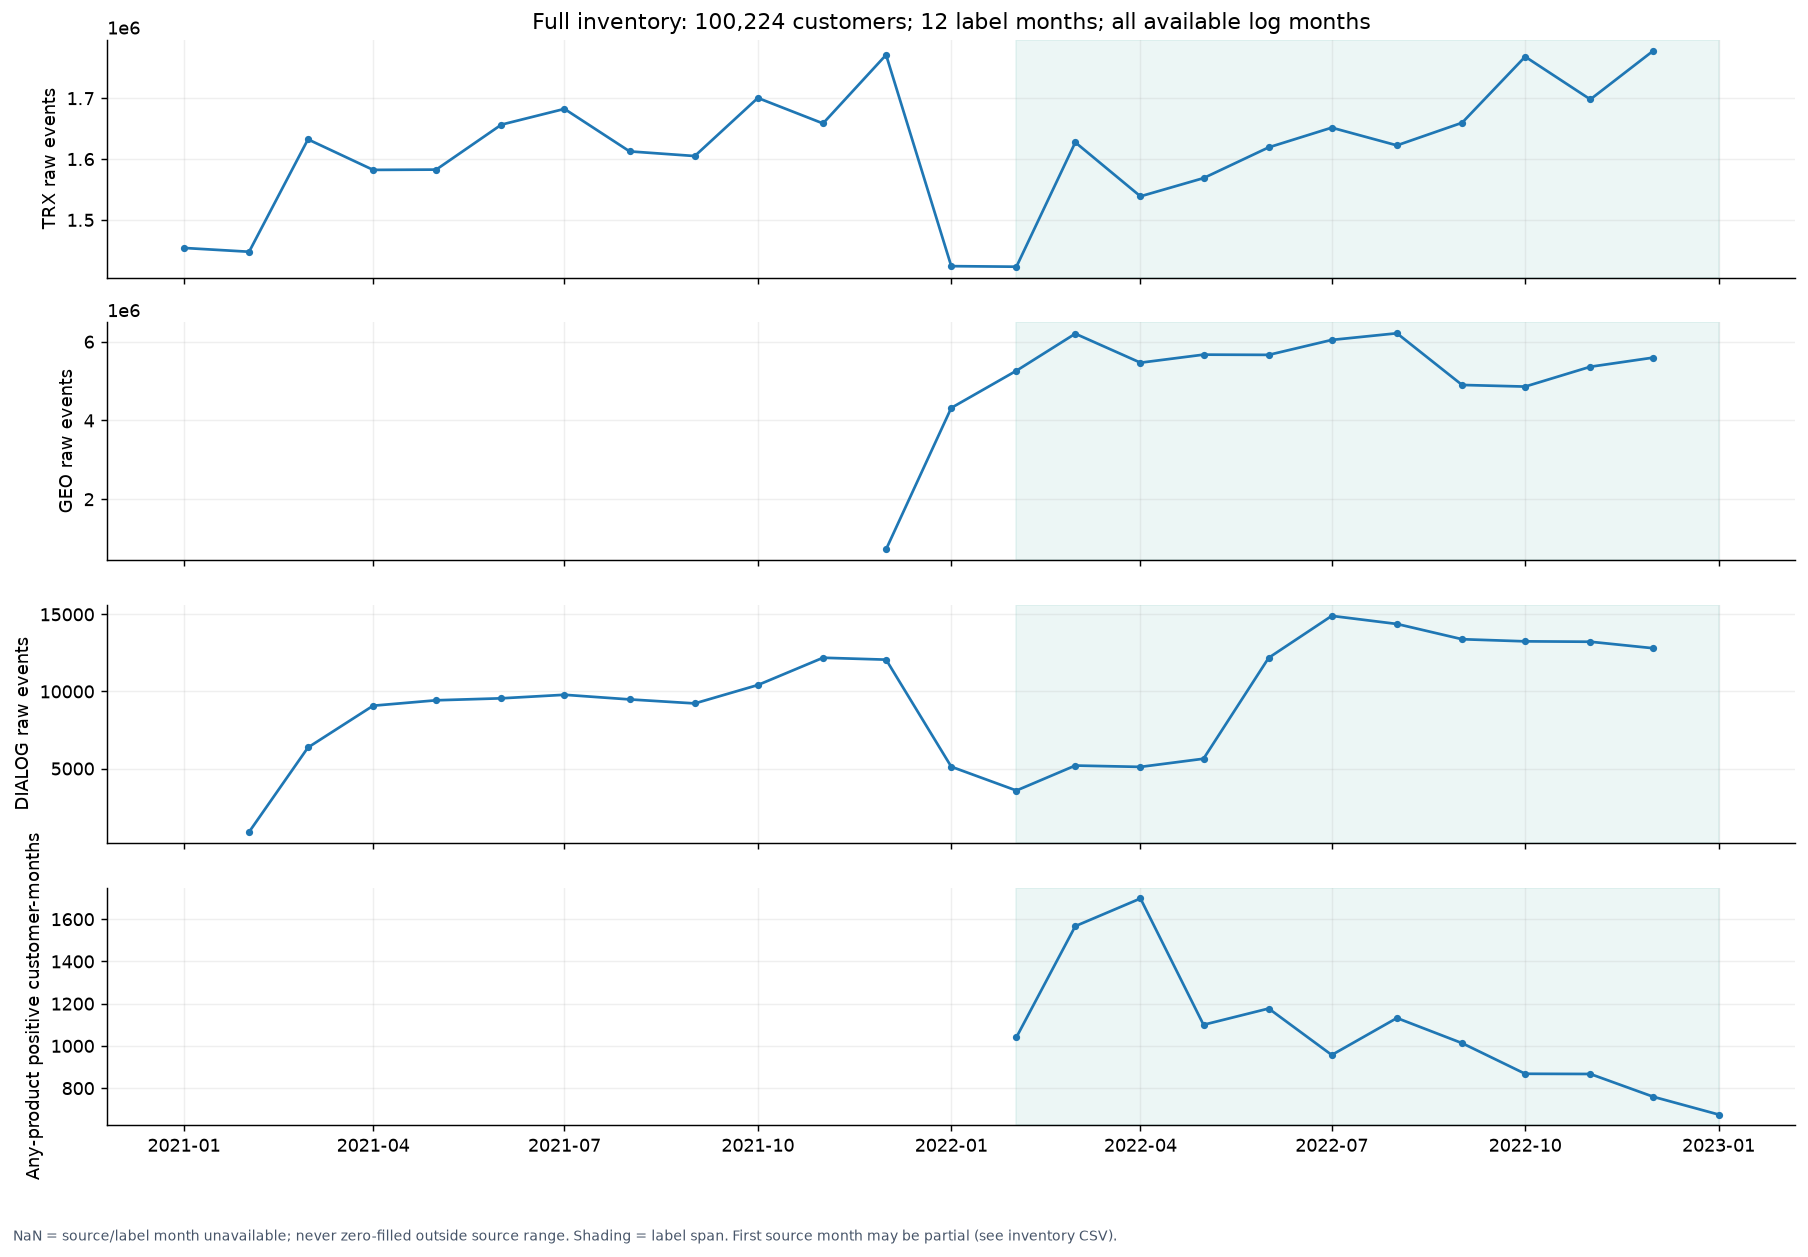

**outputs/full_population_temporal_eda_20261118/02_exhaustive_monthly_groups.png**

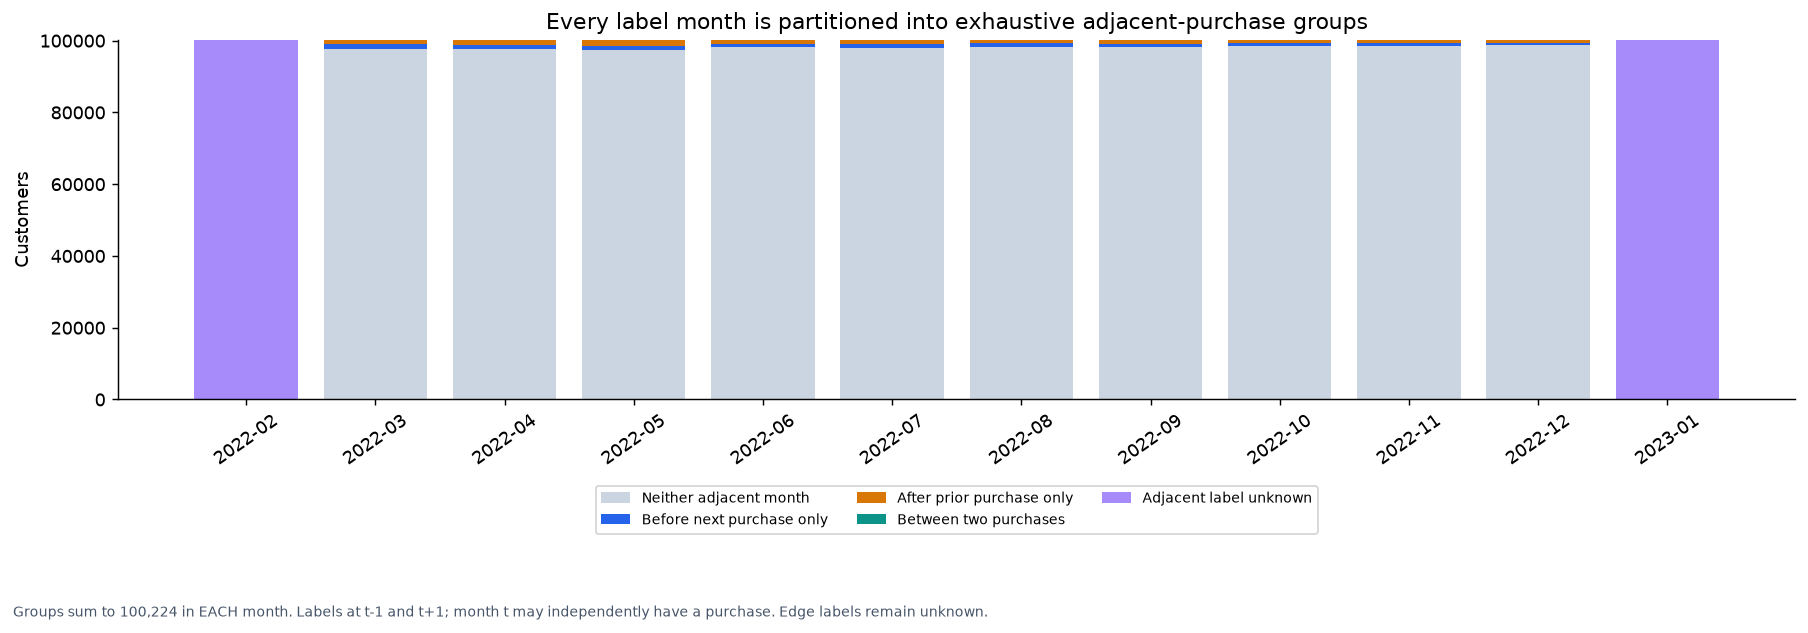

**outputs/full_population_temporal_eda_20261118/03_before_vs_after_all_label_months.png**

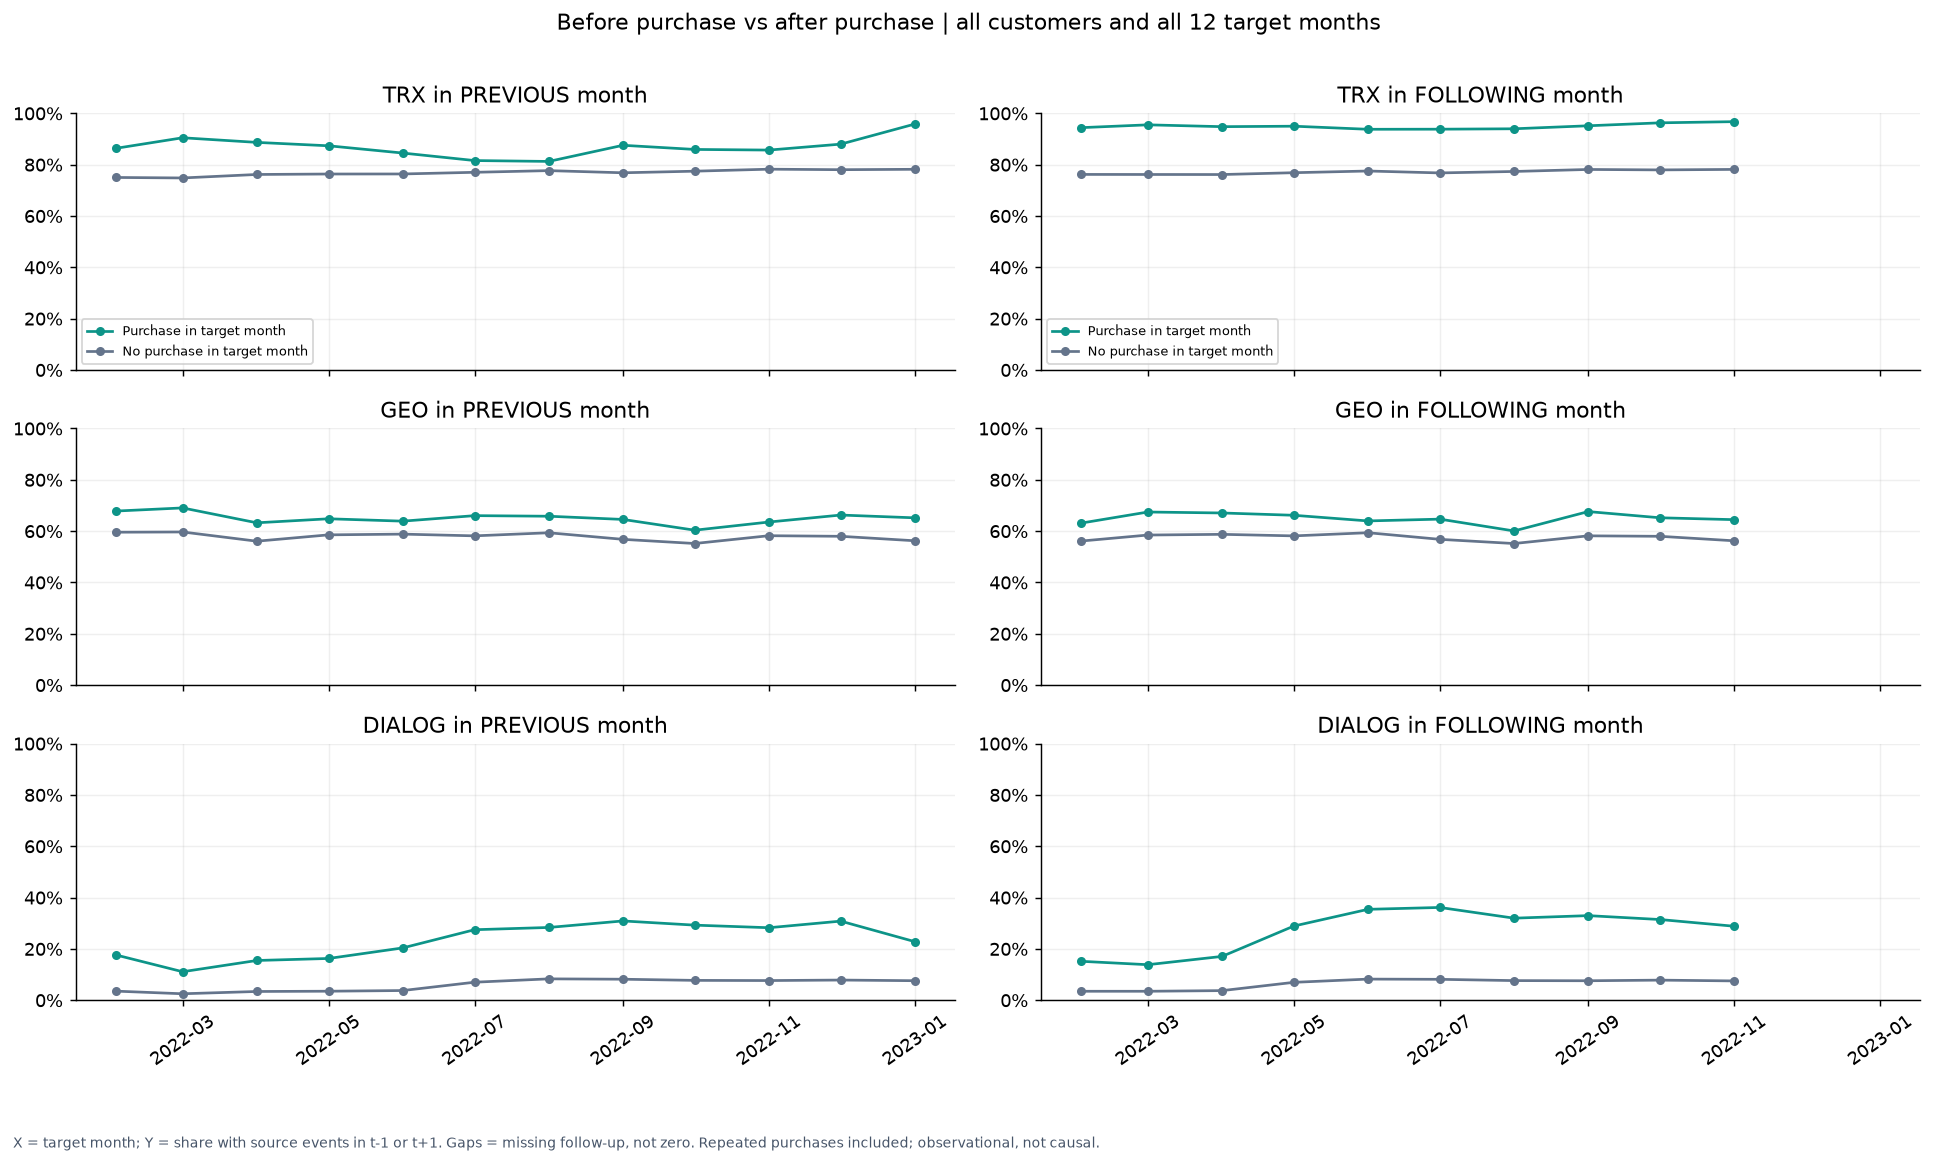

**outputs/full_population_temporal_eda_20261118/04_prior_next_purchase_groups.png**

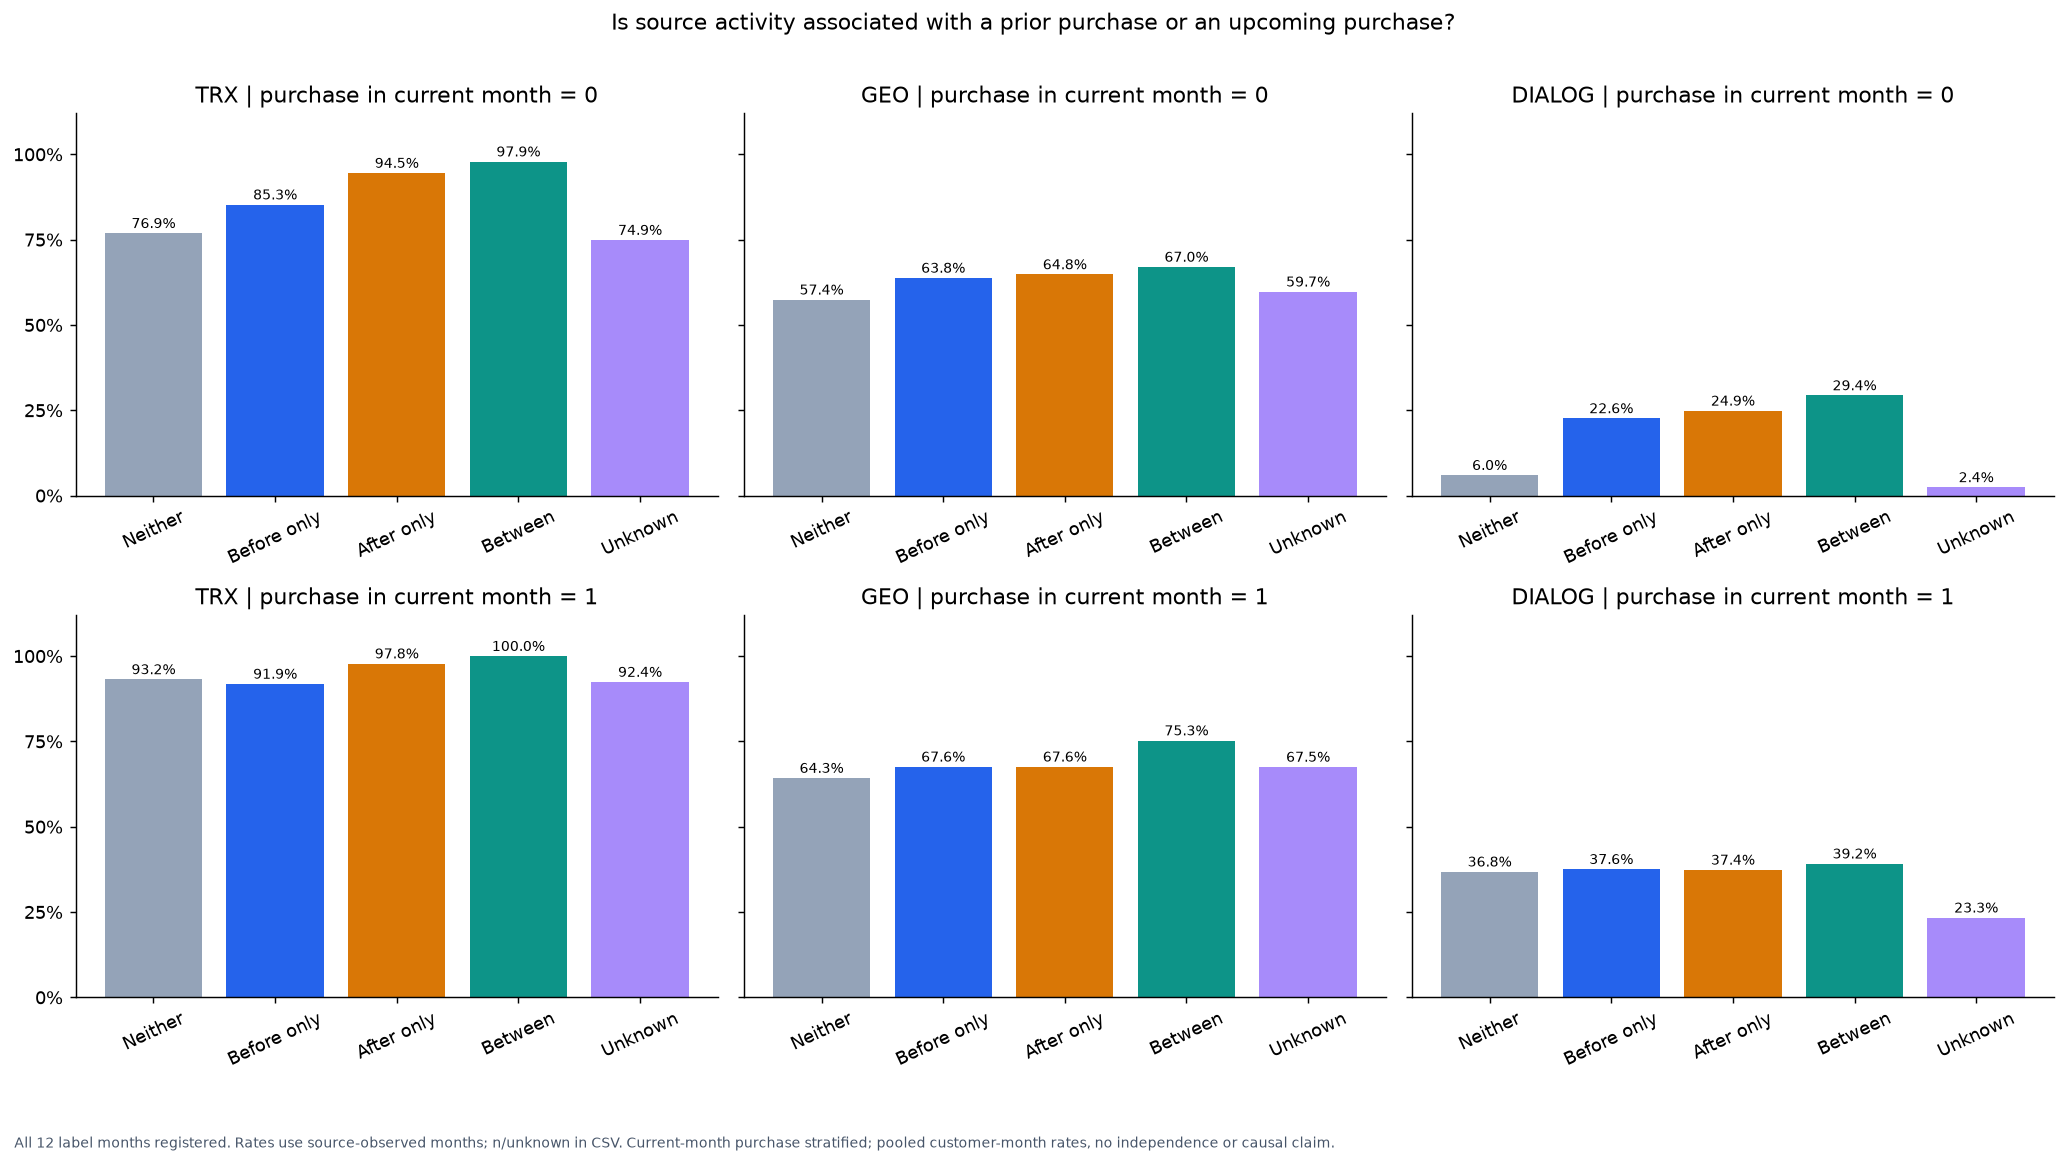

**outputs/full_population_temporal_eda_20261118/05_full_history_financial_contribution.png**

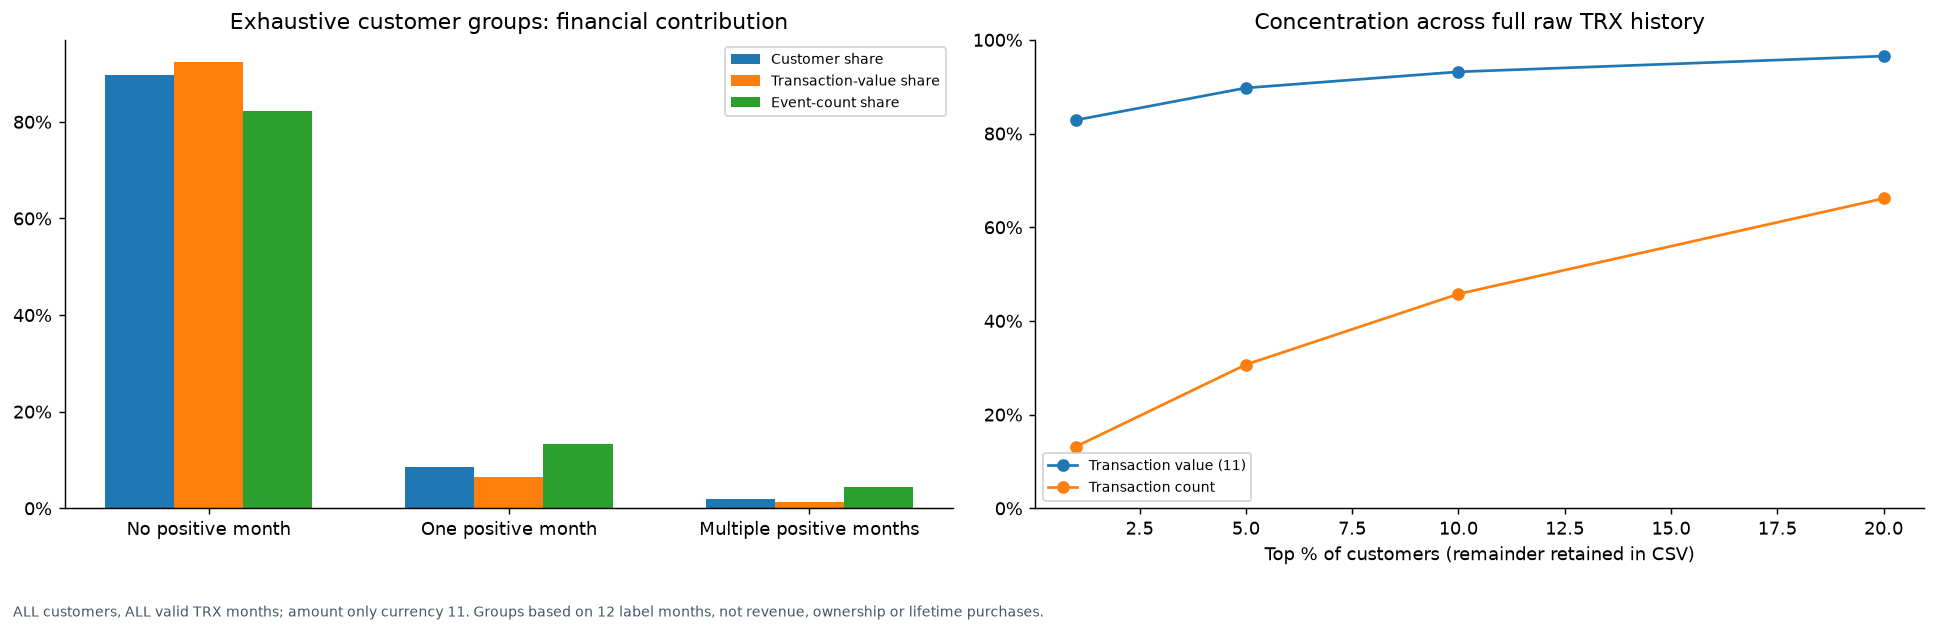

**outputs/full_population_temporal_eda_20261118/06_full_population_source_order.png**

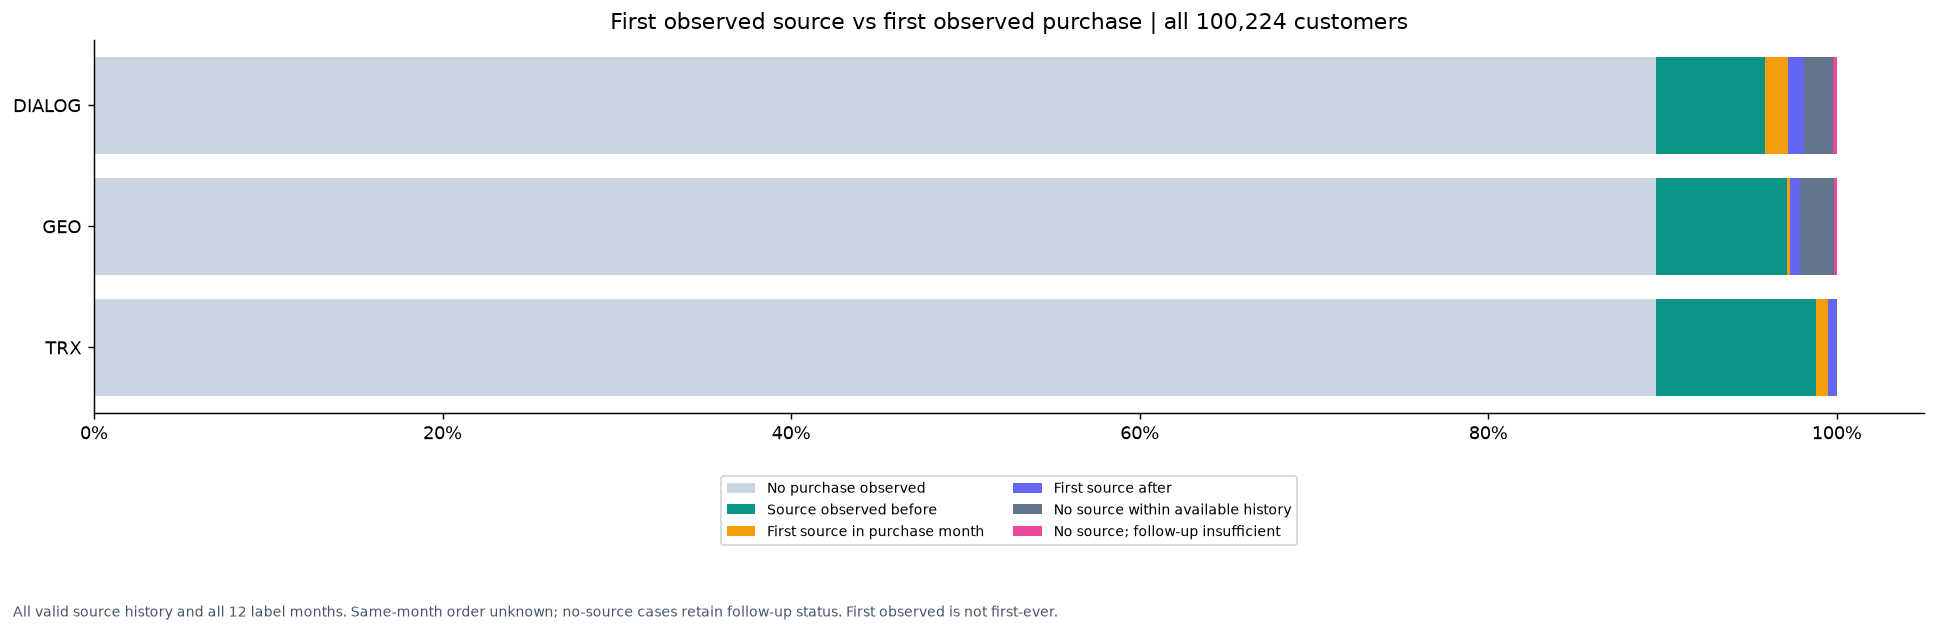

**outputs/full_population_temporal_eda_20261118/adjacent_purchase_source_associations.csv** — 5 dòng đầu

,state,current_purchase,source,total_customer_months,observed_customer_months,unavailable_customer_months,active,rate
0,Adjacent label unknown,0,trx,198732,99183,99549,74281,0.748929
1,Adjacent label unknown,0,geo,198732,99183,99549,59256,0.597441
2,Adjacent label unknown,0,dialog,198732,99183,99549,2415,0.024349
3,Adjacent label unknown,1,trx,1716,1041,675,962,0.924111
4,Adjacent label unknown,1,geo,1716,1041,675,703,0.675312


**outputs/full_population_temporal_eda_20261118/before_after_monthly_rate_ratios.csv** — 5 dòng đầu

,target_month,lag,source,nonbuyer_rate,buyer_rate,rate_ratio
0,2022-02-01,-1,dialog,0.035510,0.176753,4.977543
1,2022-02-01,-1,geo,0.595828,0.678194,1.138238
2,2022-02-01,-1,trx,0.750219,0.863593,1.151120
3,2022-02-01,1,dialog,0.034935,0.151777,4.344506
4,2022-02-01,1,geo,0.561286,0.631124,1.124425


**outputs/full_population_temporal_eda_20261118/before_after_monthly_rates.csv** — 5 dòng đầu

,target_month,lag,purchase,source,total_customers,observed_customers,unavailable_customers,active_customers,rate
0,2022-02-01,-1,0,trx,99183,99183,0,74409,0.750219
1,2022-02-01,-1,0,geo,99183,99183,0,59096,0.595828
2,2022-02-01,-1,0,dialog,99183,99183,0,3522,0.035510
3,2022-02-01,-1,1,trx,1041,1041,0,899,0.863593
4,2022-02-01,-1,1,geo,1041,1041,0,706,0.678194


... (9 outputs left out)

,month,Neither adjacent month,Before next purchase only,After prior purchase only,Between two purchases,Adjacent label unknown
0,2022-02-01,0,0,0,0,100224
1,2022-03-01,97569,1614,957,84,0
2,2022-04-01,97626,1031,1498,69,0
3,2022-05-01,97433,1093,1614,84,0
4,2022-06-01,98219,905,1048,52,0


**outputs/full_population_temporal_eda_20261118/source_inventory.csv** — 5 dòng đầu

,source,raw_rows,first_event_moscow,last_event_moscow,first_month,last_month,first_month_partial
0,trx,38764930,2021-01-01 00:00:02.169545,2022-12-31 23:59:58.460193,2021-01-01,2022-12-01,False
1,geo,66295724,2021-12-11 22:27:07.507106,2022-12-31 23:59:58.725788,2021-12-01,2022-12-01,True
2,dialog,217205,2021-02-10 12:36:07.022271,2022-12-31 23:25:11.730797,2021-02-01,2022-12-01,True


File kết quả khác: `outputs/full_population_temporal_eda_20261118/REPORT.md`, `outputs/full_population_temporal_eda_20261118/all_customer_financial_groups.parquet`, `outputs/full_population_temporal_eda_20261118/all_customer_months.parquet`, `outputs/full_population_temporal_eda_20261118/dialog_monthly.parquet`, `outputs/full_population_temporal_eda_20261118/geo_monthly.parquet`, `outputs/full_population_temporal_eda_20261118/label_month_panel_with_states.parquet`, `outputs/full_population_temporal_eda_20261118/labels_any.parquet`, `outputs/full_population_temporal_eda_20261118/manifest.json`, `outputs/full_population_temporal_eda_20261118/trx_monthly.parquet`, `outputs/full_population_temporal_eda_20261118/validation.json`

In [11]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_full_population_temporal_eda.py')